# HeTCo trên dữ liệu Reddit thật — trực quan từng bước

Notebook này đi từ **dataset Reddit 2015** đến **dự đoán sự kiện community** và so sánh HeTCo với baseline mạnh nhất B4.

- Dữ liệu: bản chuẩn bị `reddit-2015-reproduced-v1`, gồm 12 tháng 2015, mạng trả lời R theo tháng và community Leiden.
- Câu hỏi: biết một community ở tháng *t*, dự đoán ở tháng *t+1* nó sẽ **stable / grow / shrink / merge / split / dissolve**.
- Train: các tháng nhãn trước 2015-10. Test (main window): tháng nhãn 2015-10..12, gồm 571 community.
- Nhãn là pseudo-label từ GED. Dữ liệu 2015 đã được xem trong quá trình phát triển, nên đây là **bằng chứng phát triển**, chưa phải kiểm định.

Output đã được lưu sẵn để xem trên GitHub. Muốn chạy lại thì cần các artifact local liệt kê ở cell đầu.

In [1]:
import os, sys, csv, json, sqlite3
from collections import Counter
from pathlib import Path
ROOT = Path(os.environ.get("REDDIT_SNA_PROJECT", Path.cwd())).resolve()
assert (ROOT / "pyproject.toml").is_file(), "Set REDDIT_SNA_PROJECT to the repository root"
PREP = ROOT / "artifacts/core/reddit-2015-reproduced-v1"
RESEARCH = ROOT / "artifacts/research/midterm-thanh-001"
V4 = ROOT / "artifacts/hetco/hetco-v4-001"
for p in (PREP, RESEARCH, V4):
    assert p.is_dir(), f"Missing local artifact {p}"
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from reddit_sna.evaluation.research import EVENTS, score
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
print("Interpreter:", sys.executable)

Interpreter: D:\MXH\reddit-community-evolution\.venv\Scripts\python.exe


## 1. Dataset: Reddit 2015 trông như thế nào?

**5,006,366 bài/bình luận** của **205,282 người dùng** trong **393,057 thread**, thuộc **12 subreddit chính trị**, 12 tháng 2015.

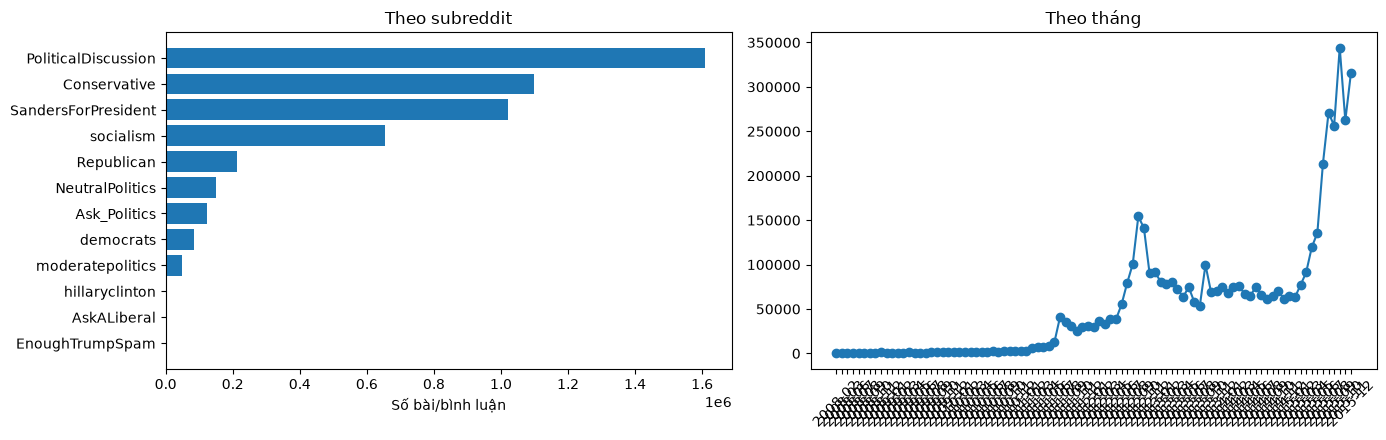

In [2]:
db = sqlite3.connect(f"file:{PREP / 'normalized.sqlite'}?mode=ro", uri=True)
records = pd.read_sql("SELECT corpus, month, COUNT(*) AS records, COUNT(DISTINCT user_id) AS users FROM records GROUP BY corpus, month", db)
total = pd.read_sql("SELECT COUNT(*) AS records, COUNT(DISTINCT user_id) AS users, COUNT(DISTINCT root) AS threads FROM records", db)
db.close()
display(Markdown(f"**{int(total.records[0]):,} bài/bình luận** của **{int(total.users[0]):,} người dùng** trong **{int(total.threads[0]):,} thread**, thuộc **{records.corpus.nunique()} subreddit chính trị**, 12 tháng 2015."))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_corpus = records.groupby("corpus").records.sum().sort_values()
axes[0].barh(by_corpus.index, by_corpus.values); axes[0].set_xlabel("Số bài/bình luận"); axes[0].set_title("Theo subreddit")
by_month = records.groupby("month")[["records"]].sum()
axes[1].plot(by_month.index, by_month.records, marker="o"); axes[1].set_title("Theo tháng"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); plt.show()

**Community Leiden trên mạng trả lời R mỗi tháng.** Mỗi người thuộc đúng một community trong tháng đó.

,month,communities,members,largest,median
0,2015-01,129,8222,2209,2
1,2015-02,105,8229,2074,2
2,2015-03,115,9357,2211,2
3,2015-04,98,11947,2405,2
4,2015-05,128,16485,5241,2
5,2015-06,143,17553,5480,2
6,2015-07,217,22778,7464,2
7,2015-08,285,28642,9412,2
8,2015-09,277,28240,8455,2
9,2015-10,308,36570,9830,2


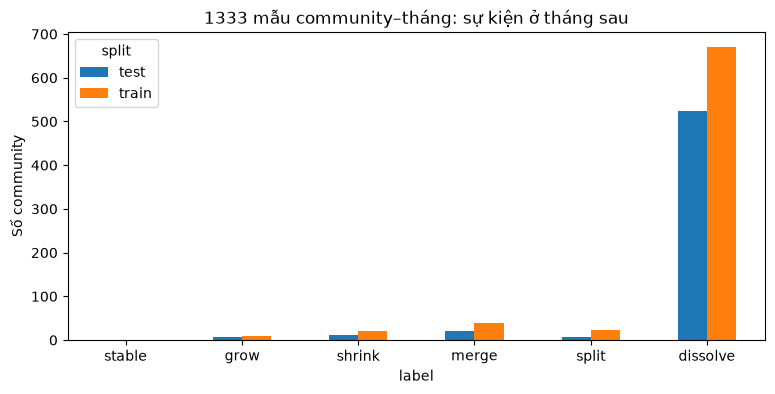

Dataset **rất lệch**: 525 trên 571 community trong test bị **dissolve**. Lớp stable không có mẫu nào trong test, nên macro-F1 6 lớp của mọi mô hình tối đa chỉ khoảng 0.83.

In [3]:
membership = []
for month in sorted(p.name for p in (PREP / "memberships").iterdir()):
    with (PREP / f"memberships/{month}/membership-seed0.csv").open(encoding="utf-8") as s:
        sizes = Counter(r["community_id"] for r in csv.DictReader(s))
    membership.append(dict(month=month, communities=len(sizes), members=sum(sizes.values()),
                           largest=max(sizes.values()), median=int(np.median(list(sizes.values())))))
membership = pd.DataFrame(membership)
display(Markdown("**Community Leiden trên mạng trả lời R mỗi tháng.** Mỗi người thuộc đúng một community trong tháng đó."))
display(membership)
samples = pd.read_csv(RESEARCH / "samples.csv")
samples["split"] = np.where(samples.label_month < "2015-10", "train", "test")
counts = samples.groupby(["split", "label"]).size().unstack(0).reindex(EVENTS).fillna(0).astype(int)
ax = counts.plot.bar(figsize=(9, 4), rot=0, title=f"{len(samples)} mẫu community–tháng: sự kiện ở tháng sau")
ax.set_ylabel("Số community"); plt.show()
display(Markdown(f"Dataset **rất lệch**: {counts.loc['dissolve','test']} trên {counts['test'].sum()} community trong test bị **dissolve**. Lớp stable không có mẫu nào trong test, nên macro-F1 6 lớp của mọi mô hình tối đa chỉ khoảng 0.83."))

## 2. Bên trong một community thật

HeTCo nhìn **từng thành viên**. Mỗi người có 13 đặc trưng, đều chỉ dùng dữ liệu đến tháng *t*:

- Mức độ hoạt động, độ mạnh liên kết trả lời, tenure, …
- Vị trí trong mạng: coreness, cầu nối sang community khác.
- Mức độ bền vững so với tháng trước: còn giữ liên kết trả lời cũ không, còn ở cùng nhóm với các thành viên cũ không.

**Attention** quyết định người nào ảnh hưởng nhiều tới dự đoán. Dưới đây là một community trong tập test mà **HeTCo_v4 đoán đúng còn B4 đoán sai**.

In [4]:
from reddit_sna.features.members import MEMBER_FEATURES, EXTENDED_FEATURES
from reddit_sna.pipelines.hetco import MODELS, _fit_predict, load_samples
rows = load_samples(RESEARCH, PREP, extended=True)
pred = pd.read_csv(V4 / "predictions.csv")
b4 = pd.read_csv(RESEARCH / "predictions.csv").query("model == 'B4_logreg' and window == 'main' and seed == 42")
main = pred.query("window == 'main' and seed == 42").pivot_table(index=["feature_month", "community_id", "y_true"], columns="model", values="y_pred", aggfunc="first").reset_index()
main = main.merge(b4[["feature_month", "community_id", "y_pred"]].rename(columns={"y_pred": "B4_logreg"}), on=["feature_month", "community_id"])
main = main.merge(samples[["feature_month", "community_id", "size"]], on=["feature_month", "community_id"])
wins = main[(main.HeTCo_v4 == main.y_true) & (main.B4_logreg != main.y_true)]
display(Markdown(f"Có **{len(wins)} community** mà v4 đúng còn B4 sai (seed 42). Mình chọn community lớn nhất để xem bên trong:"))
display(wins[["feature_month", "community_id", "size", "y_true", "B4_logreg", "HeTCo_v4"]].sort_values("size"))
case = wins.sort_values("size").iloc[-1]
display(Markdown(f"**Community `{case.community_id}`, tháng {case.feature_month}, {case['size']} thành viên.** Tháng sau thực tế: **{case.y_true}**. B4 đoán: {case.B4_logreg}. HeTCo_v2 đoán: {case.HeTCo_v2}. **HeTCo_v4 đoán: {case.HeTCo_v4}**."))
train = [r for r in rows if r["label_month"] < "2015-10"]
target = [r for r in rows if r["feature_month"] == case.feature_month and r["community_id"] == case.community_id]
fitted, _, alpha = _fit_predict(MODELS["HeTCo_v4"], train, target, 42)
with (PREP / f"memberships/{case.feature_month}/membership-seed0.csv").open(encoding="utf-8") as s:
    users = sorted(r["user_id"] for r in csv.DictReader(s) if r["community_id"] == case.community_id)
table = pd.DataFrame(target[0]["bag_extended"], columns=MEMBER_FEATURES + EXTENDED_FEATURES, index=users)
table.insert(0, "attention", alpha[0])
display(table.sort_values("attention", ascending=False).head(12).round(3))

Có **9 community** mà v4 đúng còn B4 sai (seed 42). Mình chọn community lớn nhất để xem bên trong:

,feature_month,community_id,size,y_true,B4_logreg,HeTCo_v4
50,2015-09,c173,2,grow,dissolve,grow
241,2015-10,c181,2,dissolve,grow,dissolve
432,2015-11,c143,2,merge,dissolve,merge
468,2015-11,c195,2,merge,dissolve,merge
394,2015-10,c87,3,merge,dissolve,merge
387,2015-10,c79,3,merge,dissolve,merge
363,2015-10,c42,5,grow,dissolve,grow
369,2015-10,c5,2599,shrink,split,shrink
531,2015-11,c4,2617,shrink,split,shrink


**Community `c4`, tháng 2015-11, 2617 thành viên.** Tháng sau thực tế: **shrink**. B4 đoán: split. HeTCo_v2 đoán: shrink. **HeTCo_v4 đoán: shrink**.

,attention,log_records,log_strength,internal_share,log_partners,log_tenure,previous_active,corpus_count,log_coreness,tie_persistence,comember_persistence,log_bridging,reciprocity,observed_from_start
u000185978,0.099,4.700,5.323,0.990,4.727,1.609,1.0,1.0,2.890,0.098,0.385,1.099,0.552,0.0
u000204390,0.096,5.106,5.525,0.968,4.844,1.099,1.0,1.0,2.890,0.071,0.385,1.099,0.453,0.0
u000186122,0.077,3.871,4.317,0.986,4.078,1.099,1.0,1.0,2.773,0.052,0.385,0.693,0.225,0.0
u000180065,0.067,5.451,5.919,0.981,5.030,1.609,1.0,1.0,2.890,0.237,0.385,0.693,0.533,0.0
u000152225,0.065,5.017,5.493,0.959,4.927,1.792,1.0,1.0,2.890,0.197,0.385,1.386,0.450,0.0
u000173681,0.055,3.367,4.369,0.987,4.127,1.099,1.0,1.0,2.773,0.016,0.385,0.693,0.444,0.0
u000191243,0.055,4.220,4.625,0.980,4.143,1.099,1.0,1.0,2.773,0.113,0.385,1.099,0.392,0.0
u000190313,0.051,3.611,4.190,0.954,3.989,1.099,1.0,1.0,2.773,0.038,0.385,1.099,0.250,0.0
u000186002,0.048,3.611,4.344,0.974,4.007,1.099,1.0,1.0,2.773,0.019,0.385,1.099,0.296,0.0
u000190366,0.040,4.913,5.278,0.990,4.804,0.693,0.0,1.0,2.890,0.000,0.000,0.693,0.376,0.0


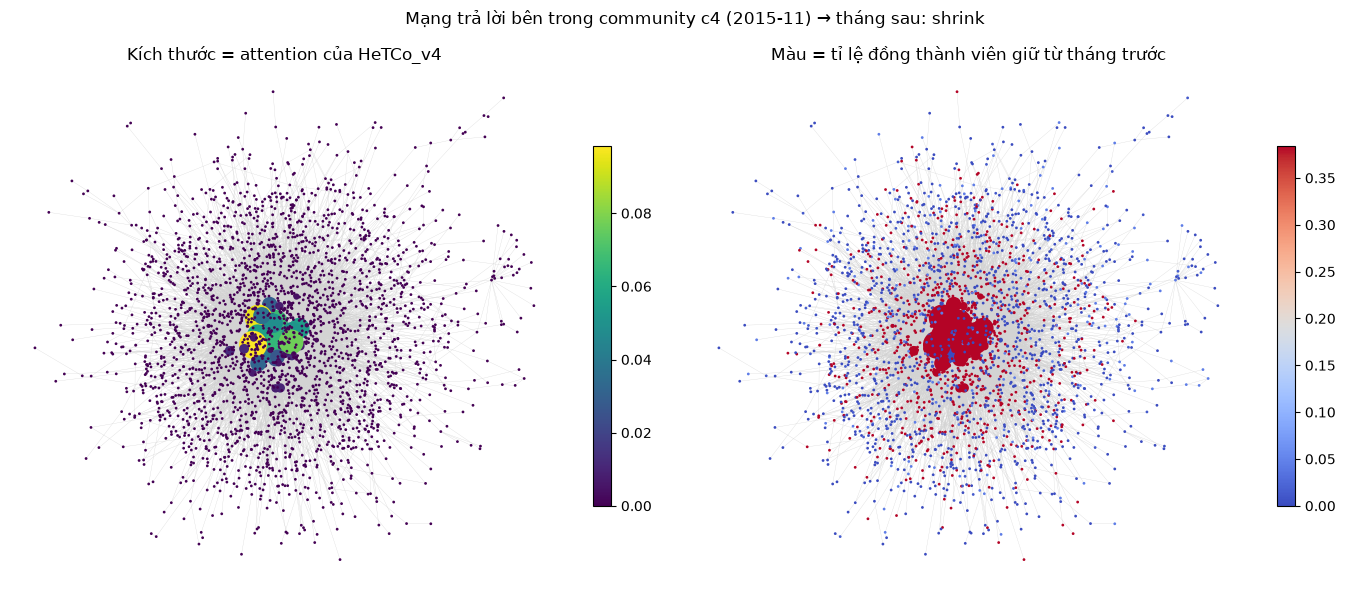

In [5]:
import igraph, random
from matplotlib.collections import LineCollection
random.seed(0)
edges = pd.read_csv(PREP / f"snapshots/{case.feature_month}/R.csv")
edges = edges[edges.source_user_id.isin(users) & edges.target_user_id.isin(users)]
graph = igraph.Graph.TupleList(edges[["source_user_id", "target_user_id"]].itertuples(index=False), directed=False)
names = graph.vs["name"]; xy = np.array(graph.layout_fruchterman_reingold(seed=None).coords) if graph.vcount() else np.zeros((0, 2))
weight = table.loc[names, "attention"].to_numpy(); persist = table.loc[names, "comember_persistence"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, values, title, cmap in ((axes[0], weight, "Kích thước = attention của HeTCo_v4", "viridis"),
                                (axes[1], persist, "Màu = tỉ lệ đồng thành viên giữ từ tháng trước", "coolwarm")):
    ax.add_collection(LineCollection([xy[[a, b]] for a, b in graph.get_edgelist()], colors="lightgray", lw=0.2, zorder=1))
    sc = ax.scatter(xy[:, 0], xy[:, 1], s=4 + 400 * weight / weight.max(), c=values, cmap=cmap, edgecolor="none", zorder=2)
    fig.colorbar(sc, ax=ax, shrink=0.7); ax.set_title(title); ax.axis("off")
fig.suptitle(f"Mạng trả lời bên trong community {case.community_id} ({case.feature_month}) → tháng sau: {case.y_true}")
fig.tight_layout(); plt.show()

## 3. Kết quả: HeTCo so với baseline (cùng mẫu, cùng cửa sổ, cùng seed)

window,main,rolling
model,,
B5_matched_boosting,0.289,0.278
HeTCo_v0,0.291,0.322
B4_logreg,0.361,0.378
HeTCo_v2,0.365,0.398
A7v4_mean_pool,0.349,0.375
HeTCo_v4,0.398,0.392


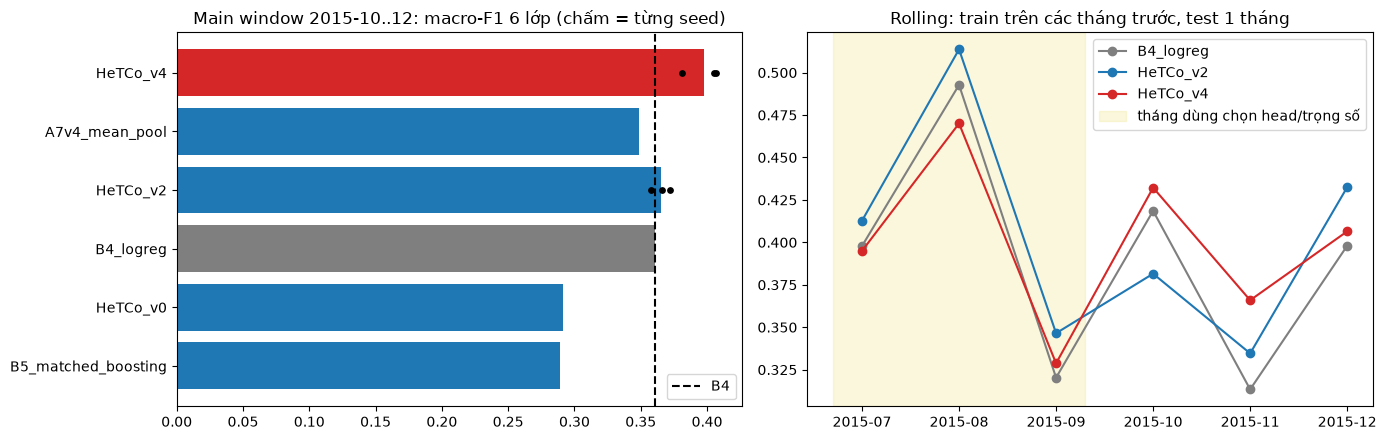

In [6]:
comparison = pd.read_csv(V4 / "comparison.csv")
view = comparison.pivot(index="model", columns="window", values="mean_macro_f1_six").loc[
    ["B5_matched_boosting", "HeTCo_v0", "B4_logreg", "HeTCo_v2", "A7v4_mean_pool", "HeTCo_v4"]]
display(view.round(3))
seed_scores = {m: [score(g.to_dict("records"))["macro_f1_six"] for _, g in pred.query("window == 'main' and model == @m").groupby("seed")]
               for m in ("HeTCo_v2", "HeTCo_v4")}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = ["tab:red" if m == "HeTCo_v4" else ("tab:gray" if m == "B4_logreg" else "tab:blue") for m in view.index]
axes[0].barh(view.index, view["main"], color=colors); axes[0].axvline(view.loc["B4_logreg", "main"], color="black", ls="--", label="B4")
for i, m in enumerate(view.index):
    if m in seed_scores:
        axes[0].scatter(seed_scores[m], [i] * 3, color="black", s=15, zorder=3)
axes[0].set_title("Main window 2015-10..12: macro-F1 6 lớp (chấm = từng seed)"); axes[0].legend()
monthly = pd.read_csv(V4 / "monthly.csv").groupby(["model", "month"]).macro_f1_six.mean().unstack(0)
for m, c in (("B4_logreg", "tab:gray"), ("HeTCo_v2", "tab:blue"), ("HeTCo_v4", "tab:red")):
    axes[1].plot(monthly.index, monthly[m], marker="o", color=c, label=m)
axes[1].axvspan(-0.3, 2.3, color="khaki", alpha=0.3, label="tháng dùng chọn head/trọng số")
axes[1].set_title("Rolling: train trên các tháng trước, test 1 tháng"); axes[1].legend()
fig.tight_layout(); plt.show()

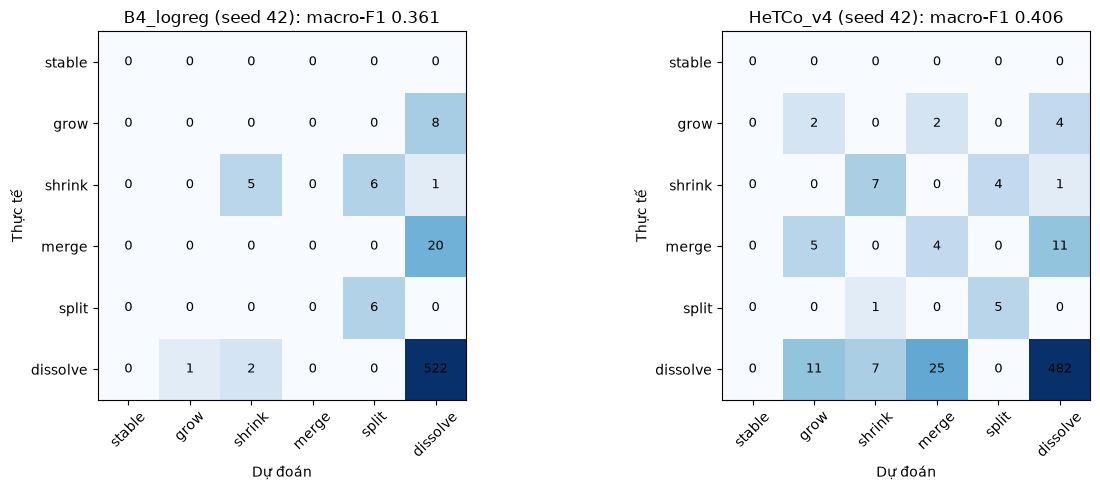

B4 gần như chỉ đoán dissolve, split và shrink, **không đoán đúng một grow hay merge nào**. HeTCo_v4 bắt được thêm grow và merge mà vẫn giữ dissolve ở mức cao.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, frame) in zip(axes, (("B4_logreg", b4), ("HeTCo_v4", pred.query("window == 'main' and seed == 42 and model == 'HeTCo_v4'")))):
    result = score(frame.assign(fallback=0).to_dict("records"))
    m = np.array(result["confusion"])
    ax.imshow(np.log1p(m), cmap="Blues"); ax.set_xticks(range(6), EVENTS, rotation=45); ax.set_yticks(range(6), EVENTS)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, m[i, j], ha="center", va="center", fontsize=9)
    ax.set_title(f"{name} (seed 42): macro-F1 {result['macro_f1_six']:.3f}"); ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
fig.tight_layout(); plt.show()
display(Markdown("B4 gần như chỉ đoán dissolve, split và shrink, **không đoán đúng một grow hay merge nào**. HeTCo_v4 bắt được thêm grow và merge mà vẫn giữ dissolve ở mức cao."))

## 4. Ví dụ cụ thể: ai đoán đúng ở đâu?

In [8]:
main["B4_dung"] = main.B4_logreg == main.y_true; main["v4_dung"] = main.HeTCo_v4 == main.y_true
summary = main.groupby("y_true")[["B4_dung", "v4_dung"]].sum().reindex(EVENTS).fillna(0).astype(int)
summary.insert(0, "so_community", main.groupby("y_true").size().reindex(EVENTS).fillna(0).astype(int))
display(Markdown("**Số community đoán đúng theo từng loại sự kiện (test, seed 42):**")); display(summary)
display(Markdown(f"v4 đúng còn B4 sai: **{int((main.v4_dung & ~main.B4_dung).sum())}** community. B4 đúng còn v4 sai: **{int((~main.v4_dung & main.B4_dung).sum())}** community."))
display(main[main.v4_dung & ~main.B4_dung].query("y_true != 'dissolve'")[["feature_month", "community_id", "size", "y_true", "B4_logreg", "HeTCo_v2", "HeTCo_v4"]].head(10))

**Số community đoán đúng theo từng loại sự kiện (test, seed 42):**

,so_community,B4_dung,v4_dung
y_true,,,
stable,0,0,0
grow,8,0,2
shrink,12,5,7
merge,20,0,4
split,6,6,5
dissolve,525,522,482


v4 đúng còn B4 sai: **9** community. B4 đúng còn v4 sai: **42** community.

,feature_month,community_id,size,y_true,B4_logreg,HeTCo_v2,HeTCo_v4
50,2015-09,c173,2,grow,dissolve,grow,grow
363,2015-10,c42,5,grow,dissolve,grow,grow
369,2015-10,c5,2599,shrink,split,split,shrink
387,2015-10,c79,3,merge,dissolve,merge,merge
394,2015-10,c87,3,merge,dissolve,merge,merge
432,2015-11,c143,2,merge,dissolve,merge,merge
468,2015-11,c195,2,merge,dissolve,merge,merge
531,2015-11,c4,2617,shrink,split,shrink,shrink


## 5. Vì sao đặc trưng mới giúp được? So sánh theo loại sự kiện

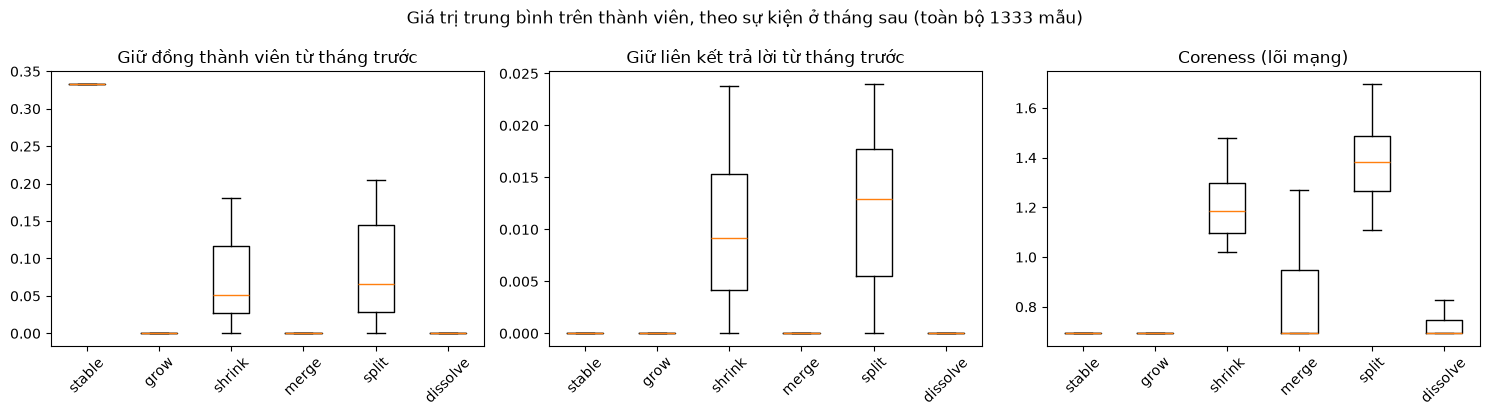

In [9]:
names = MEMBER_FEATURES + EXTENDED_FEATURES
profile = pd.DataFrame([{**dict(zip(names, r["bag_extended"].mean(axis=0))), "label": r["label"]} for r in rows])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, f, title in zip(axes, ("comember_persistence", "tie_persistence", "log_coreness"),
                        ("Giữ đồng thành viên từ tháng trước", "Giữ liên kết trả lời từ tháng trước", "Coreness (lõi mạng)")):
    data = [profile.loc[profile.label == e, f] for e in EVENTS if (profile.label == e).any()]
    ax.boxplot(data, tick_labels=[e for e in EVENTS if (profile.label == e).any()], showfliers=False)
    ax.set_title(title); ax.tick_params(axis="x", rotation=45)
fig.suptitle("Giá trị trung bình trên thành viên, theo sự kiện ở tháng sau (toàn bộ 1333 mẫu)"); fig.tight_layout(); plt.show()

## Kết luận

- **HeTCo_v4 đạt macro-F1 0.398 trên main window, B4 đạt 0.361.** Cả 3 seed đều cao hơn B4, và v4 cũng cao hơn ở cả 3 tháng rolling 10–12 không dùng để chọn.
- **Nhìn vào một community thật** (mục 2): attention của HeTCo_v4 dồn vào **lõi dày đặc gồm những người còn ở lại từ tháng trước** và bỏ qua vùng ngoại vi rời rạc. Mô hình "đọc" community qua nhóm lõi bền vững.
- **Đánh đổi:** trên tập test, v4 đúng còn B4 sai ở 9 community, B4 đúng còn v4 sai ở 42 community, chủ yếu là dissolve. v4 có macro-F1 cao hơn vì đoán đúng các lớp hiếm (grow, merge, shrink) mà B4 bỏ sót. Nếu chỉ tính accuracy thì B4 cao hơn.
- Ở mục 5, các community sắp shrink hoặc split có nhiều thành viên giữ liên kết, giữ đồng thành viên và nằm ở lõi mạng hơn. Còn community sắp dissolve, grow hay merge gần như toàn thành viên mới và ngoại vi.
- Phần tăng đến từ **thông tin quan hệ của thành viên** (giữ liên kết, giữ đồng thành viên, vị trí trong mạng), không đến từ tinh chỉnh. Attention chỉ có ích khi có các đặc trưng này: bản lấy trung bình thấp hơn 0.049.
- **Giới hạn:**
  - Khoảng tin cậy theo community trên main window vẫn chứa 0 ([−0.035, 0.110]).
  - Ý tưởng v4 hình thành sau khi xem kết quả 2015.
  - Nhãn là pseudo-label từ GED.
  - Lớp hiếm chỉ có vài chục mẫu.
- **Bước tiếp theo:** khóa v4 rồi chạy một lần trên giai đoạn chưa xem. Chi tiết số liệu ở `docs/RESULTS.md`.